In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
sns.set_style("whitegrid")
import re
from google.colab import files

In [ ]:
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
url = '/content/gdrive/MyDrive/hpv/HPV_RESULT .xlsx'
df = pd.read_excel(url, sheet_name='2324')

In [ ]:
df

,ID,Name,Age,Mobile,Result,Concentration,Result date,Unnamed: 7,Unnamed: 8,Ref doctors,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,d481193,NaN,NaN,NaN,NOT DETECTED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,d494355,NaN,NaN,NaN,NOT DETECTED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,d495452,NaN,NaN,NaN,NOT DETECTED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,d495308,NaN,NaN,NaN,NOT DETECTED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,a221811,NaN,NaN,NaN,NOT DETECTED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,D1098575,SUMONA SULTANA MOYNA,40.0,8.801760e+12,Detected 16/31 MEDIUM 22,NaN,22/12/24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
995,13 NEG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Assuming df is your dataframe
grouped_df = df.groupby(['Year', 'Result']).size().unstack(fill_value=0)

# Rename columns for better readability
grouped_df.columns = ['Negative', 'Positive']

# Modify values correctly (if Year 2024 exists)
if 2024 in grouped_df.index:
    grouped_df.loc[2024, 'Positive'] = 29
    grouped_df.loc[2024, 'Negative'] = 587

# Recalculate positive percentage
grouped_df['positive_percentage (%)'] = ((grouped_df['Positive'] / (grouped_df['Positive'] + grouped_df['Negative'])) * 100).round(2)

grouped_df


# Display final dataframe
grouped_df

# save grouped_df as csv
grouped_df.to_csv('grouped_df.csv')

KeyError: 'Year'

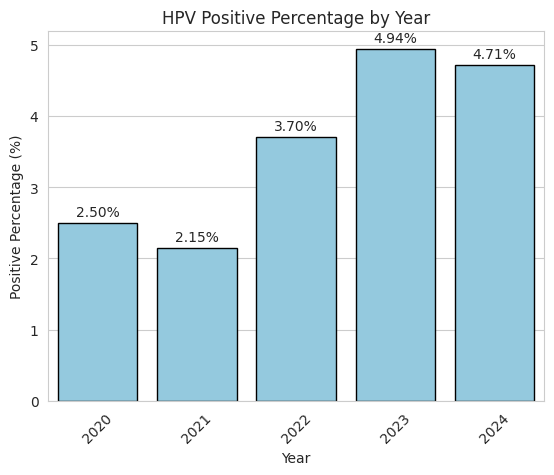

In [ ]:
ax = sns.barplot(x=grouped_df.index, y='positive_percentage (%)', data=grouped_df, color='skyblue', edgecolor='black')
plt.xticks(rotation=45)

plt.title('HPV Positive Percentage by Year')
plt.xlabel('Year')
plt.ylabel('Positive Percentage (%)')

# Add value labels directly on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', fontsize=10, padding=3)

plt.savefig("HPV_positive_percent_graph.png", dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# Create a copy of the dataframe to avoid modifying the original
age_group = df[['Age_Cat', 'Result', 'Genotype']].copy()

# Function to clean Genotype values
def refine_genotype(genotype):
    if pd.isna(genotype):  # Keep NaN values unchanged
        return None
    elif "detected other" in genotype.lower() or "other" in genotype.lower():
        return "Other Genotype"  # Assign label for 'Detected other' cases
    else:
        match = re.search(r'[\d/]+', genotype)  # Extract numerical genotypes
        return match.group(0) if match else None

# Apply the function to the Genotype column
age_group['Genotype'] = age_group['Genotype'].apply(refine_genotype)

# Display unique cleaned values
print(age_group['Genotype'].unique())  # Check the refined values


[None '18/45' '16/31' '16/18//45' '16/18' 'Other Genotype' '16' '16/18/45']


In [ ]:
# Replace incorrect genotype value
age_group['Genotype'] = age_group['Genotype'].replace('16/18//45', '16/18/45')

# Verify if the replacement was successful
age_group['Genotype'].unique()  # Check unique values after replacement


age_group = age_group[age_group['Result'] == 'Positive']
age_group = age_group.groupby(['Age_Cat', 'Genotype']).size().unstack(fill_value=0)
age_group


Genotype,16,16/18,16/18/45,16/31,18/45,Other Genotype
Age_Cat,,,,,,
Adults (25–34 years),0,0,1,18,4,1
Middle Age (35–50 years),4,2,0,20,7,0
Older Adults (50+ years),1,0,0,4,0,1
Young Adults (15–24 years),0,0,0,7,3,0


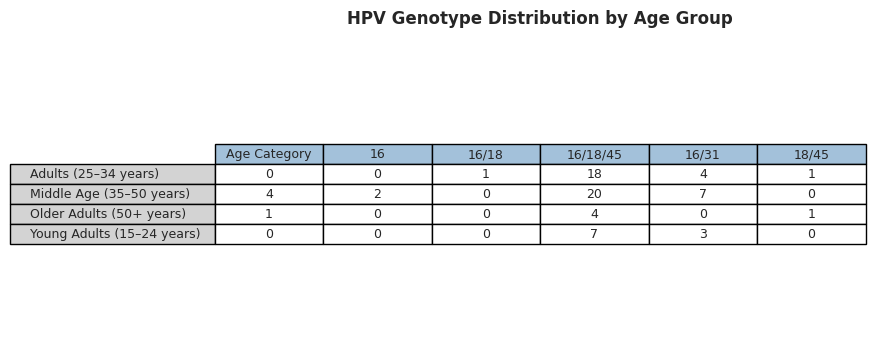

In [ ]:
# Set figure size
fig, ax = plt.subplots(figsize=(7, 4))  # Increase size for better readability

#table_df = age_group.reset_index()

# Hide axes
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)

# Modify column labels to include "Age Category" in the first column
col_labels = ["Age Category"] + list(age_group.columns)  # Adding Age Category

# Create the table with colors
table = plt.table(cellText=age_group.values,
                  colLabels=col_labels,  # Add column label "Age Category"
                  rowLabels=age_group.index,
                  cellLoc='center',
                  loc='center',
                  colColours=["#A3C1DA"] * len(col_labels),  # Light blue headers
                  rowColours=["#D3D3D3"] * len(age_group.index))  # Light gray row labels

# Set font size
table.auto_set_font_size(False)
table.set_fontsize(9)

# Adjust column width to prevent label overlap
table.scale(1.2, 1.2)  # Scale table for better spacing

# Add title
plt.text(0.5, 1.1, "HPV Genotype Distribution by Age Group", fontsize=12, ha='center', va='top', fontweight='bold', transform=ax.transAxes)

# Save as PNG
plt.savefig("HPV_Age_Genotype_Table.png", dpi=300, bbox_inches="tight")

# Show the table (optional)
plt.show()


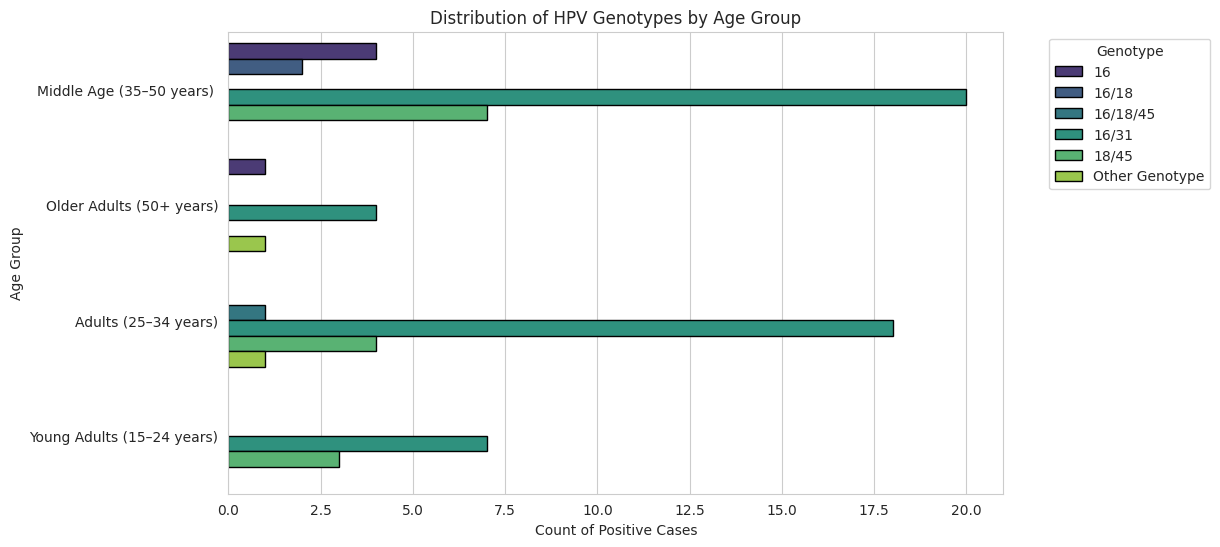

In [ ]:
# Reset index and convert to long format
age_group_reset = age_group.reset_index()
long_df = age_group_reset.melt(id_vars=['Age_Cat'], var_name='Genotype', value_name='Count')

# Remove zero-count rows to eliminate gaps
long_df = long_df[long_df['Count'] > 0]

# Plot using Seaborn - switch x and y for horizontal bars
plt.figure(figsize=(10, 6))
ax = sns.barplot(y='Age_Cat', x='Count', hue='Genotype', data=long_df, palette='viridis', edgecolor='black')

# Improve readability
plt.xlabel('Count of Positive Cases')
plt.ylabel('Age Group')
plt.title('Distribution of HPV Genotypes by Age Group')

# Move legend outside the plot
plt.legend(title='Genotype', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig("genotype_distribution.png", dpi=300, bbox_inches='tight')


# Show the plot
plt.show()

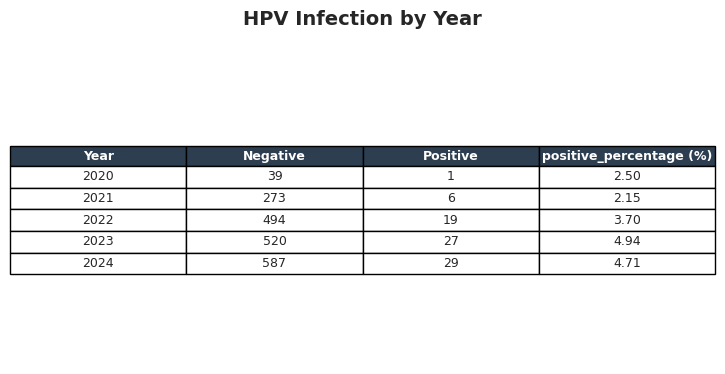

In [ ]:
# Convert dataframe to include Year as a column and remove decimals
table_df = grouped_df.reset_index()
table_df['Year'] = table_df['Year'].astype(int)  # Convert Year to integer

# Format other numerical columns to remove unnecessary decimals
for col in ["Negative", "Positive", "positive_percentage (%)"]:
    table_df[col] = table_df[col].map(lambda x: f"{x:.2f}" if isinstance(x, float) else x)  # Keeps two decimal places

# Set figure size
fig, ax = plt.subplots(figsize=(7, 4))

# Hide axes
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)

# Define column labels
col_labels = table_df.columns

# Create the table
table = plt.table(cellText=table_df.values,
                  colLabels=col_labels,  # Explicitly set column labels
                  cellLoc='center',
                  loc='center',
                  colColours=["#2C3E50"] * len(col_labels))  # Keep dark blue headers

# Set font size and improve readability
table.auto_set_font_size(False)
table.set_fontsize(9)

# Make header text white for better contrast
for (i, key) in enumerate(table._cells):
    cell = table._cells[key]
    if key[0] == 0:  # Header row
        cell.set_text_props(color="white", fontweight="bold")  # White text for visibility
        cell.set_height(0.05)  # Slightly taller headers

# Adjust column width to prevent overlap
table.scale(1.3, 1.3)

# Add a title
plt.text(0.5, 1.15, "HPV Infection by Year", fontsize=14, ha='center', va='top', fontweight='bold', transform=ax.transAxes)

# Save as PNG
plt.savefig("HPV_results_yearwise.png", dpi=300, bbox_inches="tight")

# Show the table (optional)
plt.show()

In [ ]:
#files.download("HPV_results_yearwise.png")
#files.download('HPV_positive_percent_graph.png')
#files.download("HPV_Age_Genotype_Table.png")
#files.download("genotype_distribution.png")